$\text{\large{Section 1: Data Analysis}}$

We take a look at the kinds of data for house establishments and whether or not a bank should be put in these cities for offering loans. Here is a description on the specific analysis done.

1) Population vs median home value
   - This plot explores whether ZIP codes with larger populations also have higher median home values. We use this to identify areas where more people create higher housing demand, which may be attractive for banks due to growth potential and lending opportunities.

2) Median House Price per Sqr Ft over time
   - Tracking the median price per square foot over time by metro gives a clear view of the real estate market's appreciation, volatility, and comparative cost. This informs about long-term investment potential and hotspots of value growth.

3) Hotness metric score vs days on the market
   - By correlating the Realtor.com hotness score (a measure of demand) with the number of days properties spend on market, we measure which ZIPs are most competitive. Fast-moving, in-demand markets signal robust lending environments.

4) Market hotness over time
   - Charting the average hotness score over time captures how quickly and persistently properties are being absorbed in each metro. Rising scores suggest an increasingly dynamic and competitive market—attractive for financial services expansion.

5) Median Listing Pricing over time
   - Examining the trajectory of median listing prices by month helps assess whether home values are stable, rising, or volatile, providing a window into the market’s health and the risks for new loan originations.

6) Population vs median housing income by zip level
   - This plot visualizes how income levels vary with population across ZIPs. Areas with both large populations and high incomes may offer the richest opportunities for banks to target well-qualified borrowers.

7) Population Density vs Median Home Value by metro
   - By studying the relationship between how densely populated a ZIP is and its median home value, we see which neighborhoods are most "packed and pricey", indicating potential for both high demand and high lending volumes.

8) Affordability ratio by metro
   - The affordability ratio (median home value / median household income) helps identify markets where home prices are high relative to incomes—potentially indicating buyer stress, speculative bubbles, or, conversely, wealthy neighborhoods.

9) Population vs Median Gross Rent
   - Comparing ZIP-level population with gross rent uncovers whether larger or denser communities face greater rental costs, revealing where rental markets may be under pressure and more demand for lending products could arise.

10) Geospatial Data

   - Mapping ZIP codes by population density and home value offers an intuitive, spatial overview of where people live and how much they pay for housing, highlighting geographic pockets of opportunity or risk for branch and lending strategies.


Strongly emphasized on the population aspect of things, to see how this greatly influences the house economy in these metros.

In [350]:
#Import needed libaries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [351]:

# Load needed data from the CSV cleaned
census = pd.read_csv('census_zcta.csv')
realtor = pd.read_csv('realtor_zip_monthly.csv')


Population vs median home value

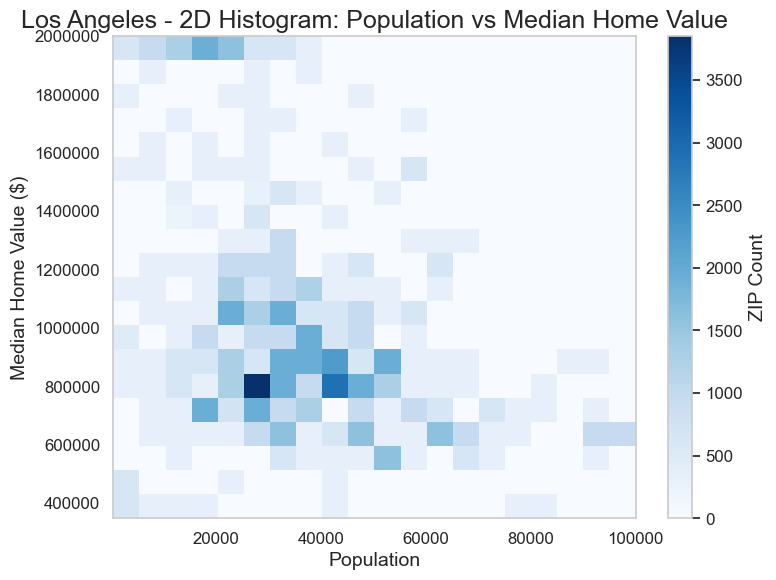

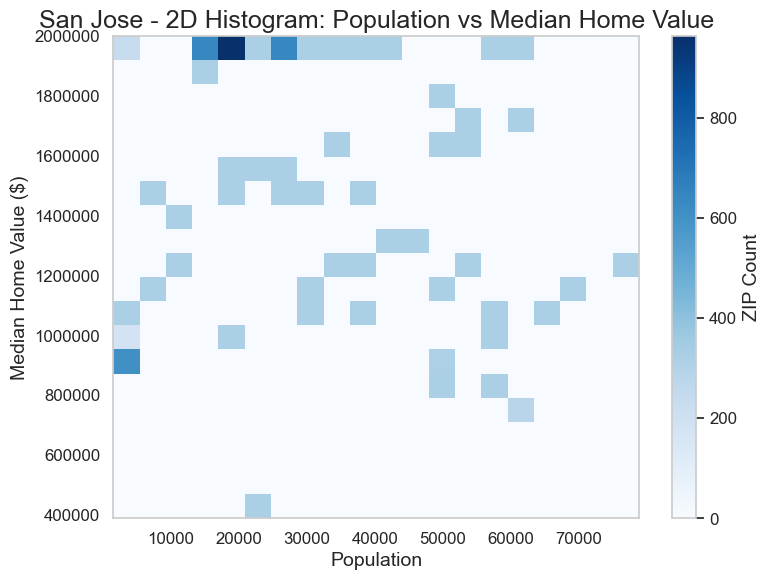

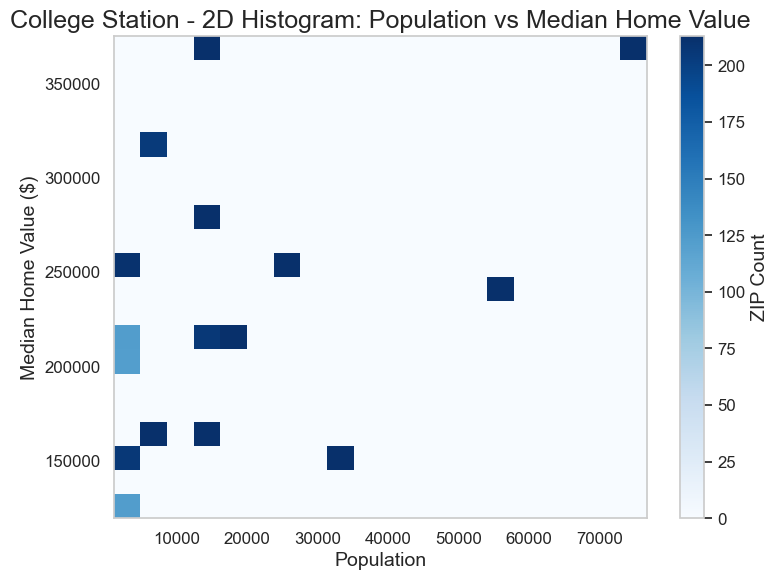

In [352]:


dat = pd.read_csv("zip_month_panel.csv")
cities = ['los_angeles', 'san_jose', 'college_station']

def prettify(metro):
    return " ".join([w.capitalize() for w in metro.split('_')])

for metro in cities:
    metro_dat = dat[dat['metro_key'] == metro]
    metro_dat_clean = metro_dat.dropna(subset=['population', 'median_home_value'])
    plt.figure(figsize=(8,6))
    plt.hist2d(metro_dat_clean['population'], metro_dat_clean['median_home_value'], bins=(20,20), cmap="Blues")
    plt.colorbar(label='ZIP Count')

    plt.ticklabel_format(style='plain', axis='x')
    plt.ticklabel_format(style='plain', axis='y')

    plt.xlabel('Population')
    plt.ylabel('Median Home Value ($)')
    plt.title(f'{prettify(metro)} - 2D Histogram: Population vs Median Home Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Median House Price per Sqr Ft over time

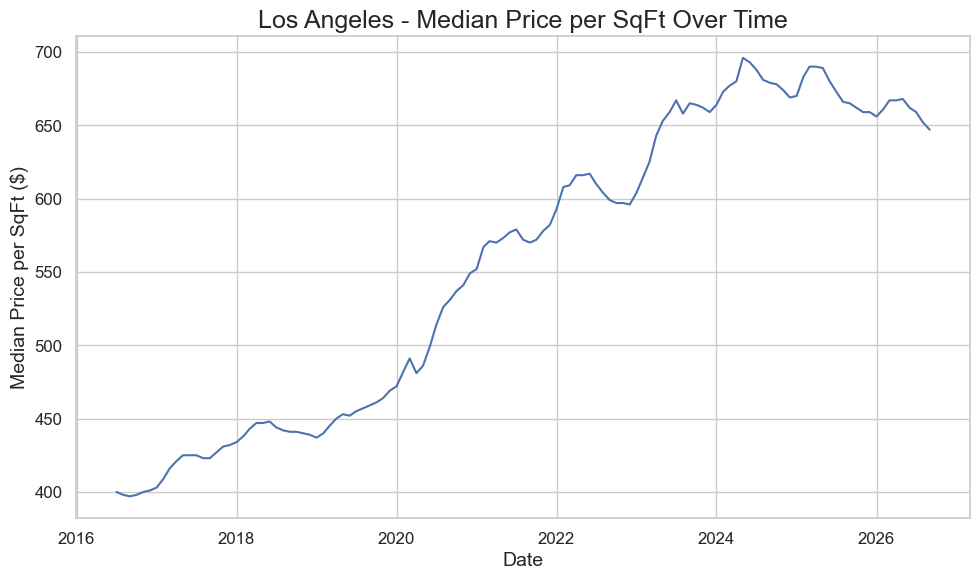

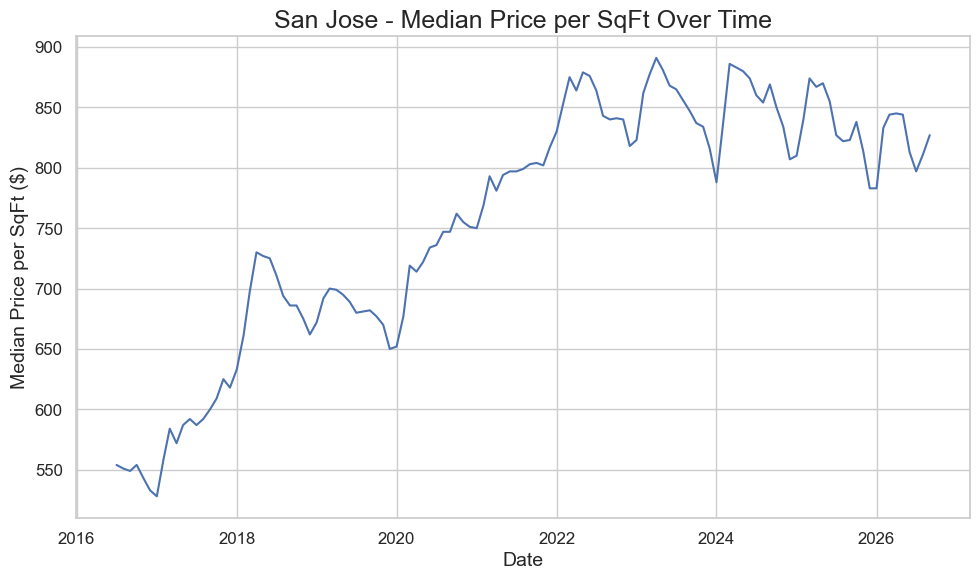

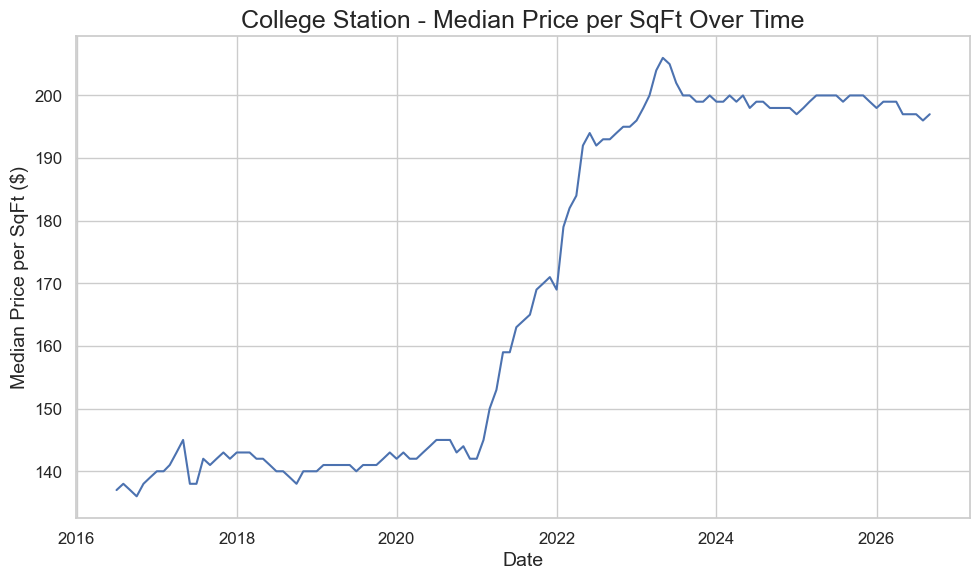

In [353]:
metro_df = pd.read_csv("realtor_metro_monthly.csv")
cities = ['los_angeles', 'san_jose', 'college_station']

for metro in cities:
    citydata = metro_df[metro_df['metro_key'] == metro]
    plt.figure(figsize=(10,6))
    plt.plot(pd.to_datetime(citydata['date']), citydata['median_listing_price_per_square_foot'])
    plt.title(f"{' '.join(metro.split('_')).title()} - Median Price per SqFt Over Time")
    plt.xlabel("Date")
    plt.ylabel("Median Price per SqFt ($)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Hotness Score vs Days on Market


Hotness score uses a mix of supply and demand scores. It measures the competitiveness of real estate markets.

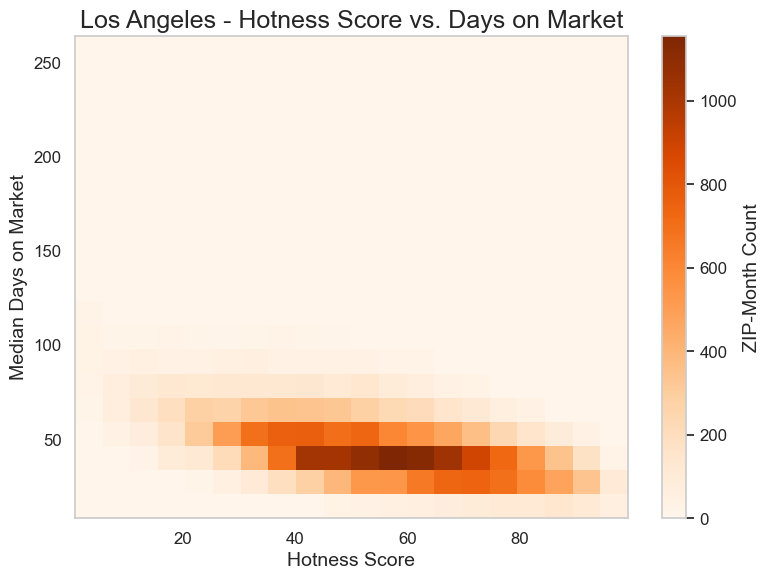

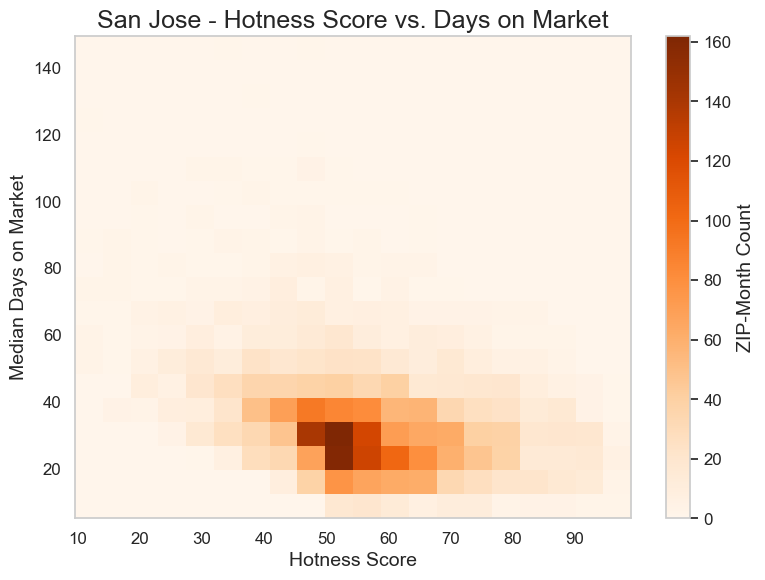

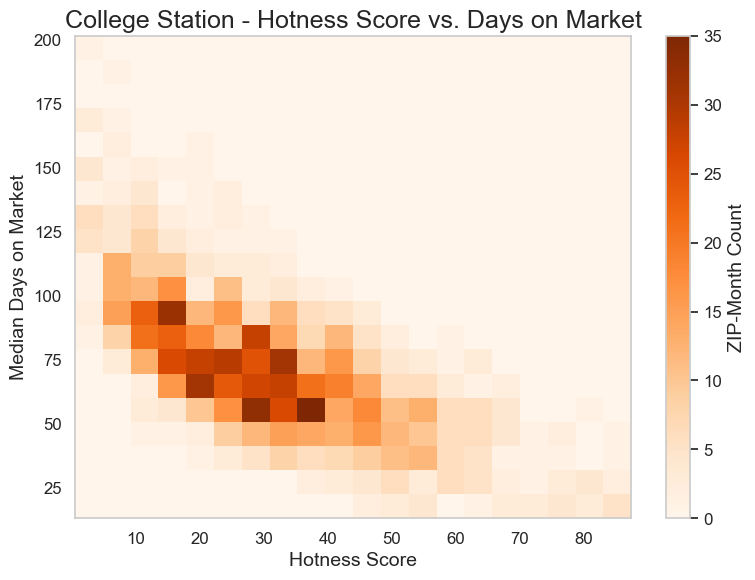

In [354]:
hotness = pd.read_csv("realtor_hotness_zip_monthly.csv")
cities = ['los_angeles', 'san_jose', 'college_station']

for metro in cities:
    data = hotness[hotness['metro_key'] == metro].dropna(subset=['hotness_score', 'median_days_on_market'])
    plt.figure(figsize=(8,6))
    plt.hist2d(
        data['hotness_score'],
        data['median_days_on_market'],
        bins=(20, 20), cmap="Oranges"
    )
    plt.colorbar(label='ZIP-Month Count')
    plt.xlabel('Hotness Score')
    plt.ylabel('Median Days on Market')
    plt.title(f"{' '.join(metro.split('_')).title()} - Hotness Score vs. Days on Market")
    plt.tight_layout()
    plt.show()

Market Hotness over months

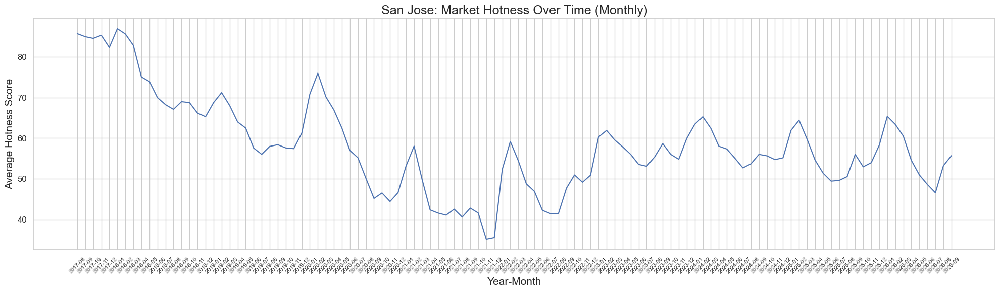

In [376]:

hotness = pd.read_csv("realtor_hotness_zip_monthly.csv")
city_hotness = hotness[hotness['metro_key'] == 'san_jose'].groupby('date').agg({'hotness_score':'mean'}).reset_index()

city_hotness['date'] = pd.to_datetime(city_hotness['date'])
# Extract year-month for grouping and labeling
city_hotness['year_month'] = city_hotness['date'].dt.to_period('M').astype(str)
month_hotness = city_hotness.groupby('year_month')['hotness_score'].mean().reset_index()

plt.figure(figsize=(20,6))
plt.plot(month_hotness['year_month'], month_hotness['hotness_score'])
plt.xlabel('Year-Month' ,size = 15)
plt.ylabel('Average Hotness Score' ,size = 15)
plt.title('San Jose: Market Hotness Over Time (Monthly)')
plt.grid(True)
plt.xticks(rotation=45 ,size = 8)
plt.tight_layout()
plt.show()

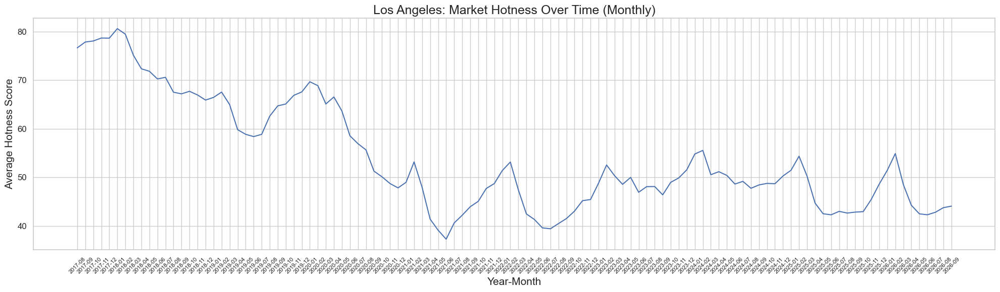

In [355]:


hotness = pd.read_csv("realtor_hotness_zip_monthly.csv")
city_hotness = hotness[hotness['metro_key'] == 'los_angeles'].groupby('date').agg({'hotness_score':'mean'}).reset_index()

city_hotness['date'] = pd.to_datetime(city_hotness['date'])
# Extract year-month for grouping and labeling
city_hotness['year_month'] = city_hotness['date'].dt.to_period('M').astype(str)
month_hotness = city_hotness.groupby('year_month')['hotness_score'].mean().reset_index()

plt.figure(figsize=(20,6))
plt.plot(month_hotness['year_month'], month_hotness['hotness_score'])
plt.xlabel('Year-Month' ,size = 15)
plt.ylabel('Average Hotness Score' ,size = 15)
plt.title('Los Angeles: Market Hotness Over Time (Monthly)')
plt.grid(True)
plt.xticks(rotation=45 ,size = 8)
plt.tight_layout()
plt.show()

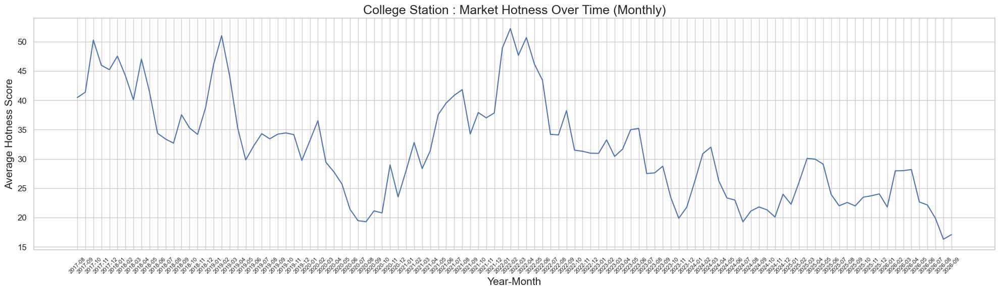

In [356]:


hotness = pd.read_csv("realtor_hotness_zip_monthly.csv")
city_hotness = hotness[hotness['metro_key'] == 'college_station'].groupby('date').agg({'hotness_score':'mean'}).reset_index()

city_hotness['date'] = pd.to_datetime(city_hotness['date'])
# Extract year-month for grouping and labeling
city_hotness['year_month'] = city_hotness['date'].dt.to_period('M').astype(str)
month_hotness = city_hotness.groupby('year_month')['hotness_score'].mean().reset_index()

plt.figure(figsize=(20,6))
plt.plot(month_hotness['year_month'], month_hotness['hotness_score'])
plt.xlabel('Year-Month' ,size = 15)
plt.ylabel('Average Hotness Score' ,size = 15)
plt.title('College Station : Market Hotness Over Time (Monthly)')
plt.grid(True)
plt.xticks(rotation=45 ,size = 8)
plt.tight_layout()
plt.show()

Median Listing Price over time

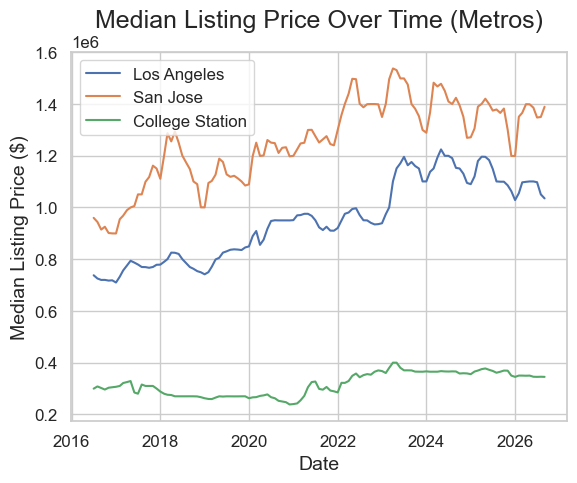

In [357]:
metro = pd.read_csv('realtor_metro_monthly.csv')

metros = ['los_angeles', 'san_jose', 'college_station']

for m in metros:
    mdf = metro[metro['metro_key'] == m]
    plt.plot(pd.to_datetime(mdf['date']), mdf['median_listing_price'], label=m.title().replace('_', ' '))

plt.xlabel("Date")
plt.ylabel("Median Listing Price ($)")
plt.title("Median Listing Price Over Time (Metros)")
plt.legend()
plt.grid(True)
plt.show()

Population  vs Median Household income 

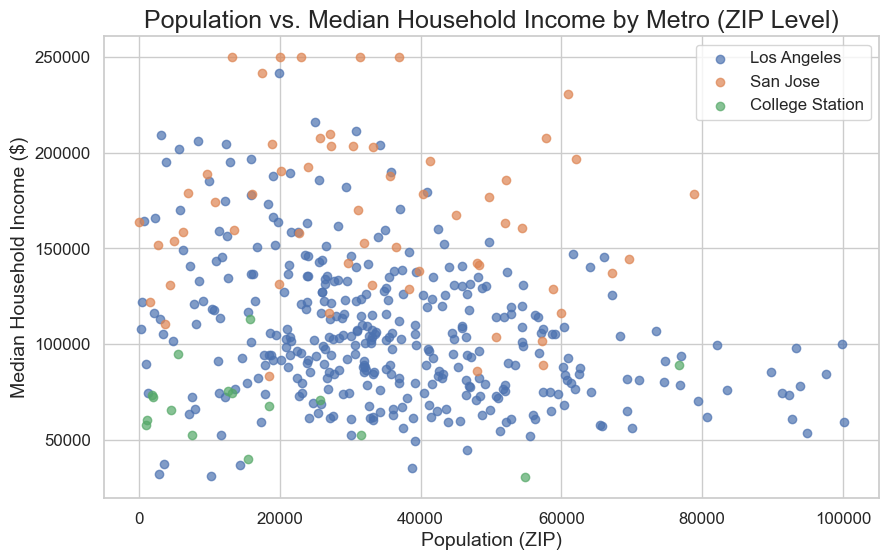

In [358]:


# Load your census data
census = pd.read_csv('census_zcta.csv')  # Use the correct file path if different

metros = {
    'los_angeles': 'Los Angeles',
    'san_jose': 'San Jose',
    'college_station': 'College Station'
}

plt.figure(figsize=(10, 6))

for key, label in metros.items():
    df = census[census['metro_key'] == key]
    plt.scatter(df['population'], df['median_household_income'], label=label, alpha=0.7)

plt.xlabel("Population (ZIP)")
plt.ylabel("Median Household Income ($)")
plt.title("Population vs. Median Household Income by Metro (ZIP Level)")
plt.legend()
plt.grid(True)
plt.show()

Population Density vs Median Home Value

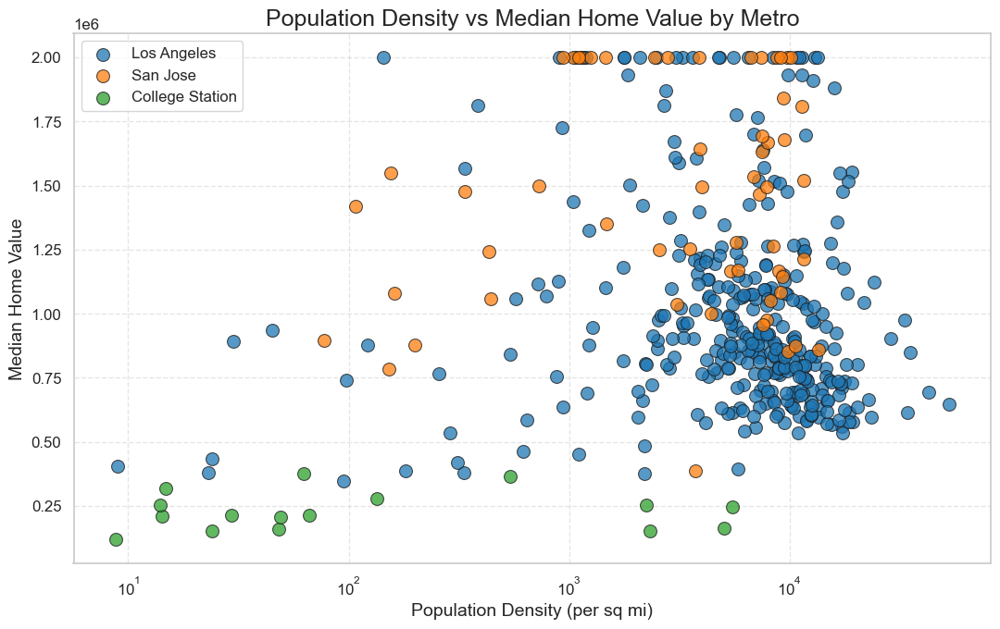

In [359]:


census = pd.read_csv('census_zcta.csv')
metros = ['los_angeles', 'san_jose', 'college_station']

sns.set(style='whitegrid', font_scale=1.1)
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['axes.labelsize'] = 14


#Format the pricing for cleaner view.
def price_fmt(x, pos):
    'Formatter for prices with commas'
    return '${:,.0f}'.format(x)


fig, ax = plt.subplots(figsize=(11, 7))
colors = sns.color_palette('tab10', len(metros))
for idx, metro in enumerate(metros):
    df = census[census['metro_key']==metro]
    sns.scatterplot(data=df, x='pop_density_per_sqmi', y='median_home_value',
                    label=metro.replace('_',' ').title(), color=colors[idx], s=100, edgecolor='k', alpha=0.75, ax=ax)
ax.set_xscale('log')
ax.set_title('Population Density vs Median Home Value by Metro')
ax.set_xlabel('Population Density (per sq mi)')
ax.set_ylabel('Median Home Value')
ax.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

Affordability Ratio

C:\Users\andri\AppData\Local\Temp\ipykernel_4632\1881753853.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


C:\Users\andri\AppData\Local\Temp\ipykernel_4632\1881753853.py:4: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



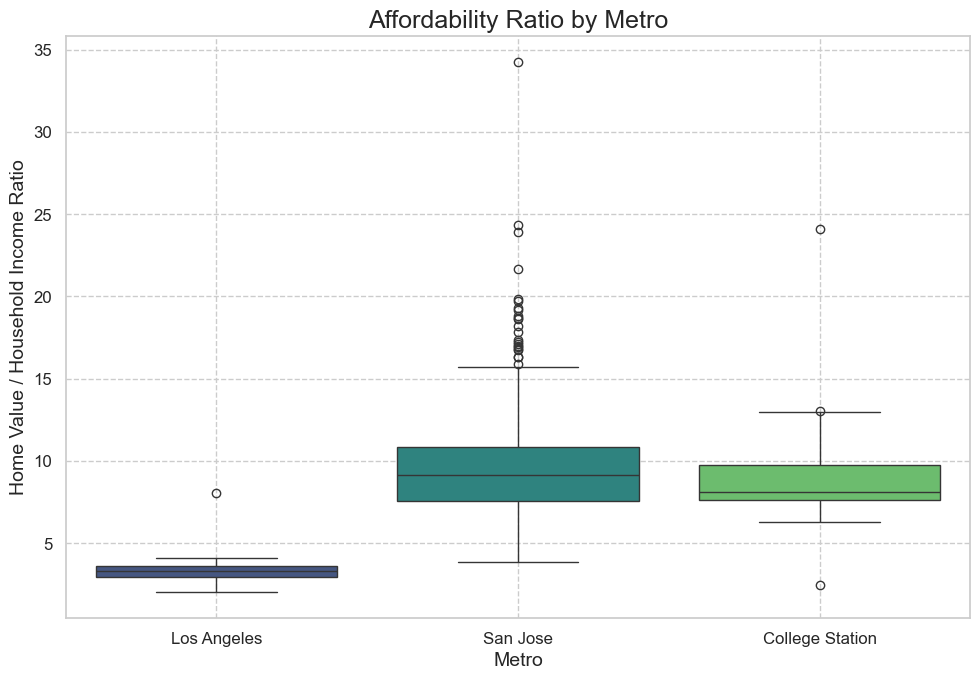

In [360]:
census['price_to_income'] = census['median_home_value'] / census['median_household_income']
fig, ax = plt.subplots(figsize=(10,7))
sns.boxplot(x='metro_key', y='price_to_income', data=census, palette='viridis', ax=ax)
ax.set_xticklabels([m.replace('_',' ').title() for m in metros])
ax.set_ylabel('Home Value / Household Income Ratio')
ax.set_xlabel('Metro')
ax.set_title('Affordability Ratio by Metro')
ax.grid(True, linestyle='--')
plt.tight_layout()
plt.show()

Population vs Median Gross Rent

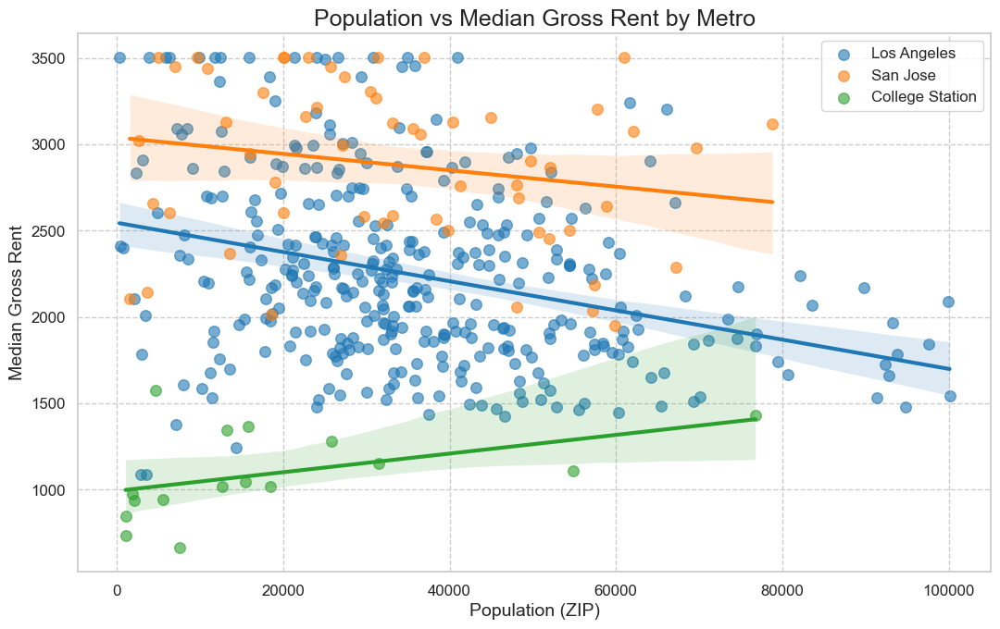

In [361]:
fig, ax = plt.subplots(figsize=(11, 7))
for idx, metro in enumerate(metros):
    df = census[census['metro_key']==metro]
    sns.regplot(x='population', y='median_gross_rent', data=df, scatter_kws={'s':70, 'alpha':0.6}, label=metro.replace('_',' ').title(), color=colors[idx], ax=ax, line_kws={'lw':3})
ax.set_title('Population vs Median Gross Rent by Metro')
ax.set_xlabel('Population (ZIP)')
ax.set_ylabel('Median Gross Rent')
ax.grid(True, linestyle='--')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

$\text{Some Geospatial Data}$

In [362]:
import plotly.express as px

# Load your data
df = pd.read_csv('zip_month_panel.csv')
fig = px.scatter_mapbox(
    df,
    lat="lat",
    lon="lon",
    color="pop_density_per_sqmi",
    hover_data=["zip", "median_home_value", "population", "median_household_income"],
    mapbox_style="open-street-map",  # No API key required
    center={"lat": 34.05, "lon": -118.25},
    zoom=8,
    opacity=0.7,
    color_continuous_scale='Viridis'
)
fig.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig.show()

C:\Users\andri\AppData\Local\Temp\ipykernel_4632\2573357686.py:5: DeprecationWarning:

*scatter_mapbox* is deprecated! Use *scatter_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/



$\text{\Large{Section 2:} {Forecasting}}$

Here we do a Forecasting with specific zip codes from each Metropolitan( 4 per each city).


Model to be used: SARIMAX.

San Jose: Using zip codes from Santa Clara

- 94022(Los Altos , Santa Clara County)

- 95054 (Santa Clara, Santa Clara County)

- 94040 (Mountain View , Santa Clara County)

- 95118 (San Jose, Santa Clara County)


Los Angeles zip codes from Los Angeles:

- 90004

- 90005

- 90232

- 90059


College Station zip codes:

- 76629

- 77801

- 77802

- 77087

Features to consider

1) population

2) median household income

3) population density per square mile

4) hotness score

5) median days on market

6) median gross rent



In [363]:
#Import the needed libraries
from statsmodels.tsa.statespace.sarimax import SARIMAX as smx
import numpy as np
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler

In [364]:

# Load data, this is the main dataset we will be using.
df = pd.read_csv('zip_month_panel.csv')


In [365]:


# List of target ZIPs for San Jose,Los Angeles, College station
sj_zips = [94022, 95054, 94040, 95118]
la_zips = [90004 , 90005,90232, 90059]
cs_zips = [76629 ,77801 ,77802 ,77087]




#Make sure to convert to datetime.
df['month'] =pd.to_datetime(df['month'])

#Make sure to convert the date for the hotness metric too.
hotness['date'] = pd.to_datetime(hotness['date'])


# Standardize ZIP-code types.
df['zip'] = pd.to_numeric(df['zip']).astype('Int64')
hotness['zip'] = pd.to_numeric(hotness['zip']).astype('Int64')


#Merge,safe for no nulls.
df = df.merge(
    hotness[['zip', 'date', 'hotness_score']],
    left_on=['zip', 'month'],
    right_on=['zip', 'date'],
    how='left',
     validate='many_to_one'
)

#Drop redundant date column.
df = df.drop(columns=['date'])

#Interpolate Null hotness score values, just to avoid any weird errors later on.
df['hotness_score'] = df.groupby('zip')['hotness_score'].transform(lambda x: x.interpolate().ffill().bfill())





In [ ]:
#This is the target feature
targ = 'rdc_median_listing_price'

#features for forecast
features = ['population', 'median_household_income', 'pop_density_per_sqmi', 'hotness_score', 
           'rdc_median_days_on_market', 'median_gross_rent']




#Numeric columns
numeric_columns = features + [targ]


#Convert to numeric
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')



# Interpolate within each ZIP code
df = df.sort_values(['zip', 'month'])
for col in features:

    df[col] = df.groupby('zip')[col].transform(
        
        lambda x: x.interpolate(
            limit_direction='both'
        ).ffill().bfill()
    )




#Filter the san jose zip codes for the forecasting 
sj_df = df[df['zip'].isin(sj_zips)].copy()
la_df = df[df['zip'].isin(la_zips)].copy()
cs_df= df[df['zip'].isin(cs_zips)].copy()



#Start year for forecast, August 1st 2017
sj_df = sj_df[sj_df['month'] >= '2017-08-01']
la_df = la_df[la_df['month'] >= '2017-08-01']
cs_df = cs_df[cs_df['month'] >= '2017-08-01']


#Function to combine the regional data together(San Jose, Los Angeles, College Station), help of chat.tamu.ai in this function
def aggregate_region(data):

    # Ensure chronological ordering
    data = data.sort_values(['zip', 'month']).copy()

    

    # Aggregate ZIP codes by month(Keep in mind to have the mean since we are aiming to predict a variable that is already an average).
    regional_data = data.groupby('month').agg({
        'rdc_median_listing_price': 'mean',
        'population': 'sum',
        'median_household_income': 'mean',
        'pop_density_per_sqmi': 'mean',
        'hotness_score': 'mean',
        'rdc_median_days_on_market': 'mean',
        'median_gross_rent': 'mean'

    })

    # Count ZIP codes contributing to each month's target
    # zip_counts = (
    #     data.groupby('month')
    #     .apply(
    #         lambda x: x.loc[
    #             x['rdc_median_listing_price'].notna(), 'zip'
    #         ].nunique(),
    #         include_groups=False
    #     )
    # )

    # Check geographic coverage
    # print("ZIP-code coverage:")
    # print(zip_counts.value_counts().sort_index())



    # Create a complete monthly index.
    full_index = pd.date_range(
        start=regional_data.index.min(),
        end=regional_data.index.max(),
        freq='MS'
    )


    regional_data = regional_data.reindex(full_index)
    regional_data.index.name = 'month'



    # Fill missing predictor values after aggregation.
    regional_data[features] = (

        regional_data[features]
        .interpolate(method='time')
        .ffill()
        .bfill()
    )
    return regional_data
  

# Aggregate all three regions.
sj_data = aggregate_region(sj_df)
la_data = aggregate_region(la_df)
cs_data = aggregate_region(cs_df)


In [371]:
#Keep the regions.
regions = {
    'San Jose': sj_data,
    'Los Angeles': la_data,
    'College Station': cs_data
}

# Store results per region when doing the forecasting.
regional_results = {}
regional_forecasts = {}

# Forecast horizon
future = 36 #3 years


# SARIMAX parameters.
for region, data in regions.items():
    print(f'\nFitting SARIMAX: {region}')
    print('\n SARIMAX Average House price prediction per month.')

    # Target variable
    target_y = data[targ].astype(float)

    # Exogenous variables
    exog = data[features].astype(float)

    # Standardize exogenous variables(may not be same scale).
    scaler = StandardScaler()


    #Scale the exogenous variables as well as a fail safe.
    exog_scaled = pd.DataFrame(

        scaler.fit_transform(exog),
        index=exog.index,
        columns=features
    )

    # Fit SARIMAX model here.
    model = smx(
        target_y,
        exog=exog_scaled,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    result = model.fit(disp=False, maxiter=500)

    # Create future monthly dates.
    future_index = pd.date_range(

        start=data.index[-1],
        periods=future + 1,
        freq='MS'
    )[1:]

    # Hold future exogenous variables constant.
    last_row = exog.iloc[-1]
    exog_future = pd.DataFrame(
        [last_row.values] * future,
        index=future_index,
        columns=features
    )

    # Apply the same scaler used during training.
    exog_future_scaled = pd.DataFrame(
        scaler.transform(exog_future),
        index=future_index,
        columns=features
    )


    # Generate forecast
    forecast = result.get_forecast(
        steps=future,
        exog=exog_future_scaled
    )


    # Save results
    regional_results[region] = {
        'model': result,
        'scaler': scaler
    }

    regional_forecasts[region] = forecast

    # Display forecast
    print(f'\n{region} forecast:')

    print(forecast.predicted_mean)

    
    #Some metrics.
    print('\nModel AIC:', result.aic)
    print('\nModel RMSE ', np.sqrt(result.mse))
    print("====================================\n")
    


Fitting SARIMAX: San Jose

 SARIMAX Average House price prediction per month.

San Jose forecast:
2026-10-01    2.119440e+06
2026-11-01    2.011727e+06
2026-12-01    2.138839e+06
2027-01-01    1.757225e+06
2027-02-01    1.640628e+06
2027-03-01    1.927316e+06
2027-04-01    2.029553e+06
2027-05-01    1.957651e+06
2027-06-01    1.859752e+06
2027-07-01    2.059710e+06
2027-08-01    2.079589e+06
2027-09-01    2.060431e+06
2027-10-01    2.063254e+06
2027-11-01    1.960027e+06
2027-12-01    2.116951e+06
2028-01-01    1.716705e+06
2028-02-01    1.601201e+06
2028-03-01    1.887536e+06
2028-04-01    1.998486e+06
2028-05-01    1.906761e+06
2028-06-01    1.810242e+06
2028-07-01    2.027060e+06
2028-08-01    2.048425e+06
2028-09-01    2.030063e+06
2028-10-01    2.031922e+06
2028-11-01    1.928373e+06
2028-12-01    2.083160e+06
2029-01-01    1.684250e+06
2029-02-01    1.568667e+06
2029-03-01    1.855027e+06
2029-04-01    1.965353e+06
2029-05-01    1.875049e+06
2029-06-01    1.778432e+06
2029-07-01

$\textbf{Brief Model Stats}$

1) SARIMAX for average house price predictions in San Jose to September 1st, 2029

- AIC: $2,299.96 

- RMSE: $37,9762.67


2) SARIMAX for average house price predictions in Los Angeles to September 1st, 2029

- AIC: $2,177.86

- RMSE: $22,6862.37

3) SARIMAX for average house price predictions in College Station to September 1st, 2029

- AIC: $1,915.48

- RMSE: $40,726.31

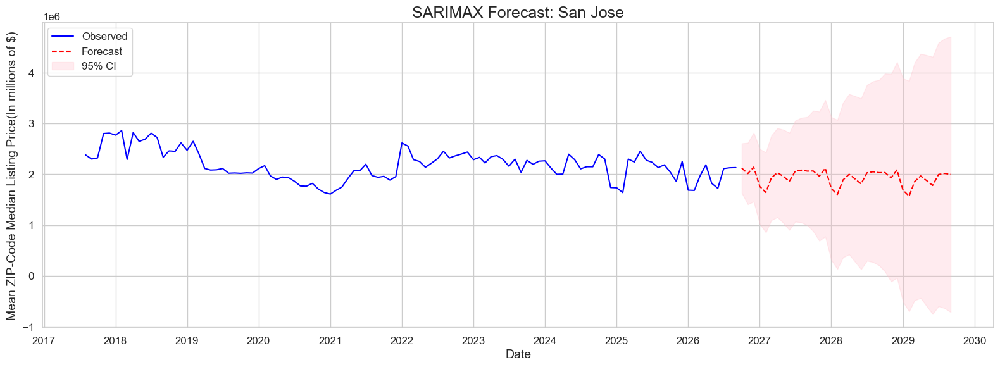

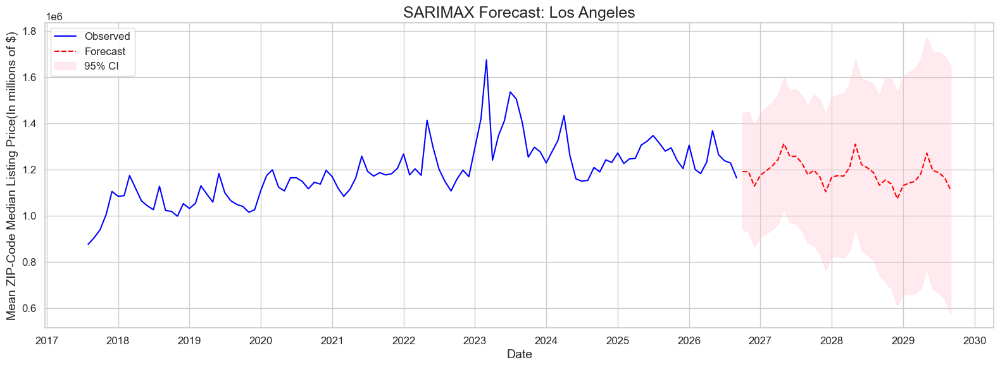

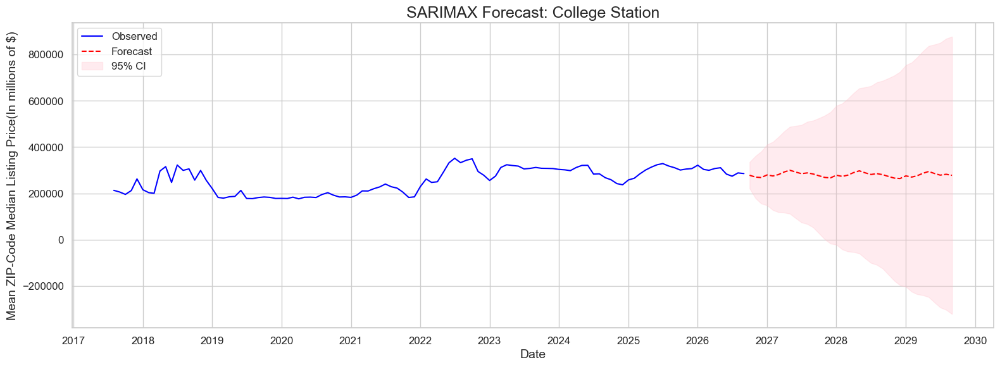

In [ ]:

#Now here we do the forecasting.
for region, data in regions.items():


    forecast = regional_forecasts[region]

    #forecast means
    forecast_mean = forecast.predicted_mean

    #Confidence intervals
    conf_int = forecast.conf_int()



    plt.figure(figsize=(16, 6))

    # Historical observations
    plt.plot(
        data.index,
        data[targ],
        color='blue',
        label='Observed'
    )

    # Forecast
    plt.plot(
        forecast_mean.index,
        forecast_mean,
        color='red',
        linestyle='--',
        label='Forecast'
    )

    # Confidence interval for uncertainty
    plt.fill_between(
        forecast_mean.index,
        conf_int.iloc[:, 0],
        conf_int.iloc[:, 1],
        color='pink',
        alpha=0.3,
        label='95% CI'
    )



    plt.xlabel('Date')
    plt.ylabel('Mean ZIP-Code Median Listing Price(In millions of $)')
    plt.title(f'SARIMAX Forecast: {region}')
    plt.legend()


    # Yearly ticks
    plt.gca().xaxis.set_major_locator(
        mdates.YearLocator()
    )

    plt.gca().xaxis.set_major_formatter(
        mdates.DateFormatter('%Y')
    )

    plt.tight_layout()
    plt.show()